[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/vvvvvivekkk/AI-Engineer/blob/main/16-careers/notebooks/03-skills-gap-self-assessment.ipynb)

# 03 · Skills gap self-assessment

Compare your skills with what six AI roles typically need, find your biggest gaps, and turn them into a week-by-week learning plan.

**What you will learn**
1. Read a **skills matrix** (skills × roles, levels 0–3) and visualise it as a heatmap.
2. Rate yourself and compute a **readiness score** per role.
3. Draw a **radar chart** comparing you with a target role.
4. Find which roles are similar (so skills transfer).
5. Generate a simple learning plan from your gaps.

Levels: **0** not needed · **1** basic awareness · **2** working knowledge · **3** strong / could teach it. The matrix is our judgement of typical entry-to-mid-level adverts (late 2026) — real JDs vary.

## Step 1 — load the matrix

The CSV has one row per skill, the course module that teaches it, and one column per role.

In [1]:
import pathlib, urllib.request

RAW = "https://raw.githubusercontent.com/vvvvvivekkk/AI-Engineer/main/16-careers/data/"

def data_path(name: str) -> pathlib.Path:
    """Find a data file locally (repo checkout) or download it (Colab)."""
    for p in [pathlib.Path("../data") / name, pathlib.Path("data") / name, pathlib.Path(name)]:
        if p.exists():
            return p
    target = pathlib.Path(name)
    urllib.request.urlretrieve(RAW + name, target)      # works in Colab once the repo is public
    return target
print("loader ready")

import pandas as pd
matrix = pd.read_csv(data_path("skills_matrix.csv"))
ROLES = [c for c in matrix.columns if c not in ("skill", "module")]
print(ROLES)
matrix.head()

loader ready


['AI Trainer / Annotator', 'Prompt Engineer', 'AI Engineer', 'ML Engineer', 'MLOps / LLMOps', 'AI Product Manager']


,skill,module,AI Trainer / Annotator,Prompt Engineer,AI Engineer,ML Engineer,MLOps / LLMOps,AI Product Manager
0,Python programming,"01, 02",1,2,3,3,3,1
1,Git & GitHub,00,0,1,3,3,3,1
2,"Data handling (pandas, SQL)",02,1,1,2,3,2,2
3,Math & statistics intuition,03,1,1,2,3,1,1
4,"Classic ML (scikit-learn, metrics)",04,0,1,2,3,2,1


## Step 2 — heatmap of what each role needs

Darker = higher level needed. Read down a column to see a role's profile; read across a row to see where a skill matters.

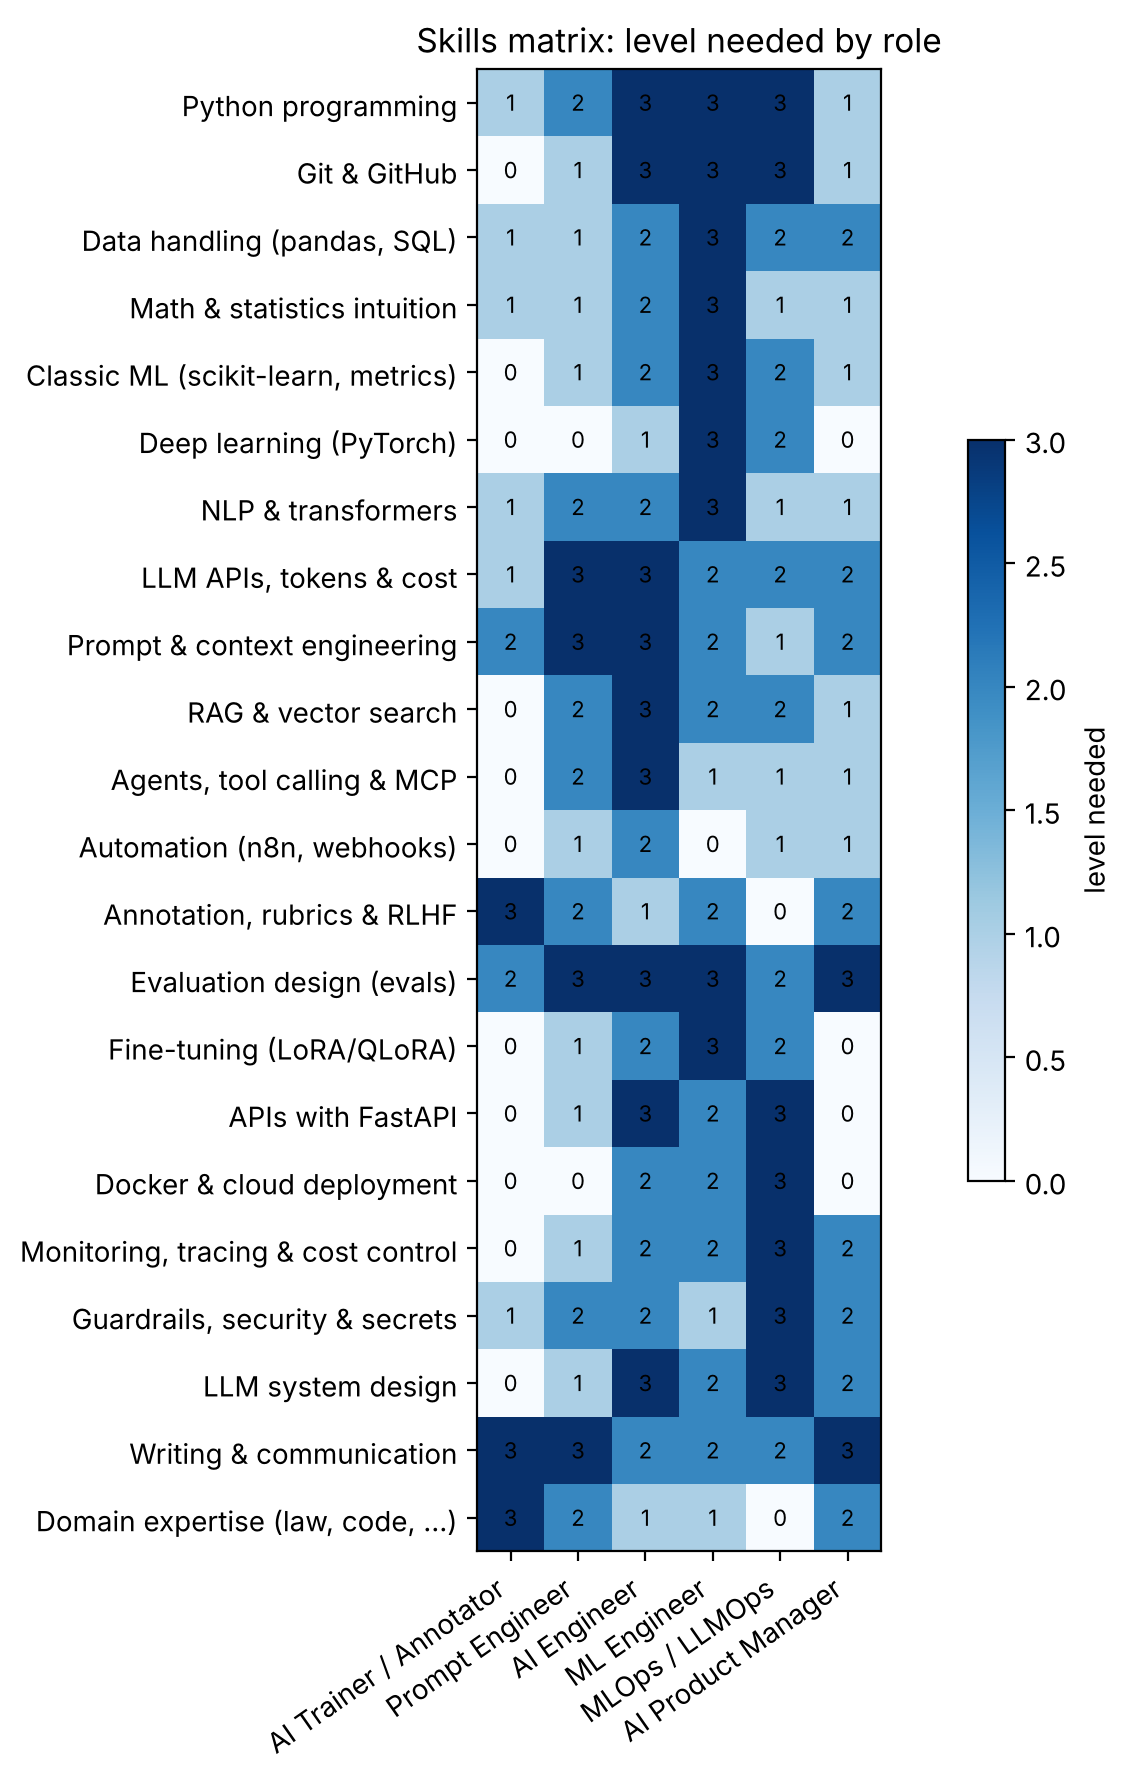

In [2]:
import matplotlib.pyplot as plt
import numpy as np
fig, ax = plt.subplots(figsize=(9, 9))
im = ax.imshow(matrix[ROLES].values, cmap="Blues", vmin=0, vmax=3)
ax.set_xticks(range(len(ROLES)), ROLES, rotation=35, ha="right")
ax.set_yticks(range(len(matrix)), matrix.skill)
for i in range(len(matrix)):
    for j in range(len(ROLES)):
        ax.text(j, i, matrix[ROLES].iat[i, j], ha="center", va="center", fontsize=8)
fig.colorbar(im, shrink=0.5, label="level needed"); ax.set_title("Skills matrix: level needed by role")
plt.tight_layout(); plt.show()

## Step 3 — rate yourself

Edit the numbers below honestly (0–3). The example is a learner who has finished the Python, data and LLM modules but not deployment yet. A rating of 3 means you could teach it.

In [3]:
my_ratings = {
    "Python programming": 3, "Git & GitHub": 2, "Data handling (pandas, SQL)": 2, "Math & statistics intuition": 1,
    "Classic ML (scikit-learn, metrics)": 2, "Deep learning (PyTorch)": 1, "NLP & transformers": 2,
    "LLM APIs, tokens & cost": 2, "Prompt & context engineering": 2, "RAG & vector search": 2,
    "Agents, tool calling & MCP": 1, "Automation (n8n, webhooks)": 0, "Annotation, rubrics & RLHF": 1,
    "Evaluation design (evals)": 1, "Fine-tuning (LoRA/QLoRA)": 0, "APIs with FastAPI": 1,
    "Docker & cloud deployment": 0, "Monitoring, tracing & cost control": 0, "Guardrails, security & secrets": 1,
    "LLM system design": 0, "Writing & communication": 2, "Domain expertise (law, code, ...)": 1,
}
matrix["me"] = matrix.skill.map(my_ratings)
assert matrix.me.notna().all(), "rate every skill"
matrix[["skill", "me"]].T

,0,1,2,3,4,5,6,7,8,9,...,12,13,14,15,16,17,18,19,20,21
skill,Python programming,Git & GitHub,"Data handling (pandas, SQL)",Math & statistics intuition,"Classic ML (scikit-learn, metrics)",Deep learning (PyTorch),NLP & transformers,"LLM APIs, tokens & cost",Prompt & context engineering,RAG & vector search,...,"Annotation, rubrics & RLHF",Evaluation design (evals),Fine-tuning (LoRA/QLoRA),APIs with FastAPI,Docker & cloud deployment,"Monitoring, tracing & cost control","Guardrails, security & secrets",LLM system design,Writing & communication,"Domain expertise (law, code, ...)"
me,3,2,2,1,2,1,2,2,2,2,...,1,1,0,1,0,0,1,0,2,1


## Step 4 — readiness per role

For each skill, the **gap** is how many levels you are short (never negative — being above the need is fine). **Readiness** = 1 − (total gap ÷ total levels needed). 100% means you meet every requirement.

In [4]:
rows = []
for role in ROLES:
    gap = (matrix[role] - matrix.me).clip(lower=0)
    rows.append({"role": role, "levels needed": int(matrix[role].sum()), "total gap": int(gap.sum()),
                 "readiness": 1 - gap.sum() / matrix[role].sum()})
readiness = pd.DataFrame(rows).sort_values("readiness", ascending=False)
readiness.style.format({"readiness": "{:.0%}"})

,role,levels needed,total gap,readiness
0,AI Trainer / Annotator,19,6,68%
5,AI Product Manager,30,11,63%
1,Prompt Engineer,35,13,63%
3,ML Engineer,48,21,56%
4,MLOps / LLMOps,42,19,55%
2,AI Engineer,50,23,54%


## Step 5 — radar chart: you vs a target role

A **radar chart** puts each skill on its own spoke; the further out, the higher the level. Where the role's shape sticks out beyond yours, there is a gap.

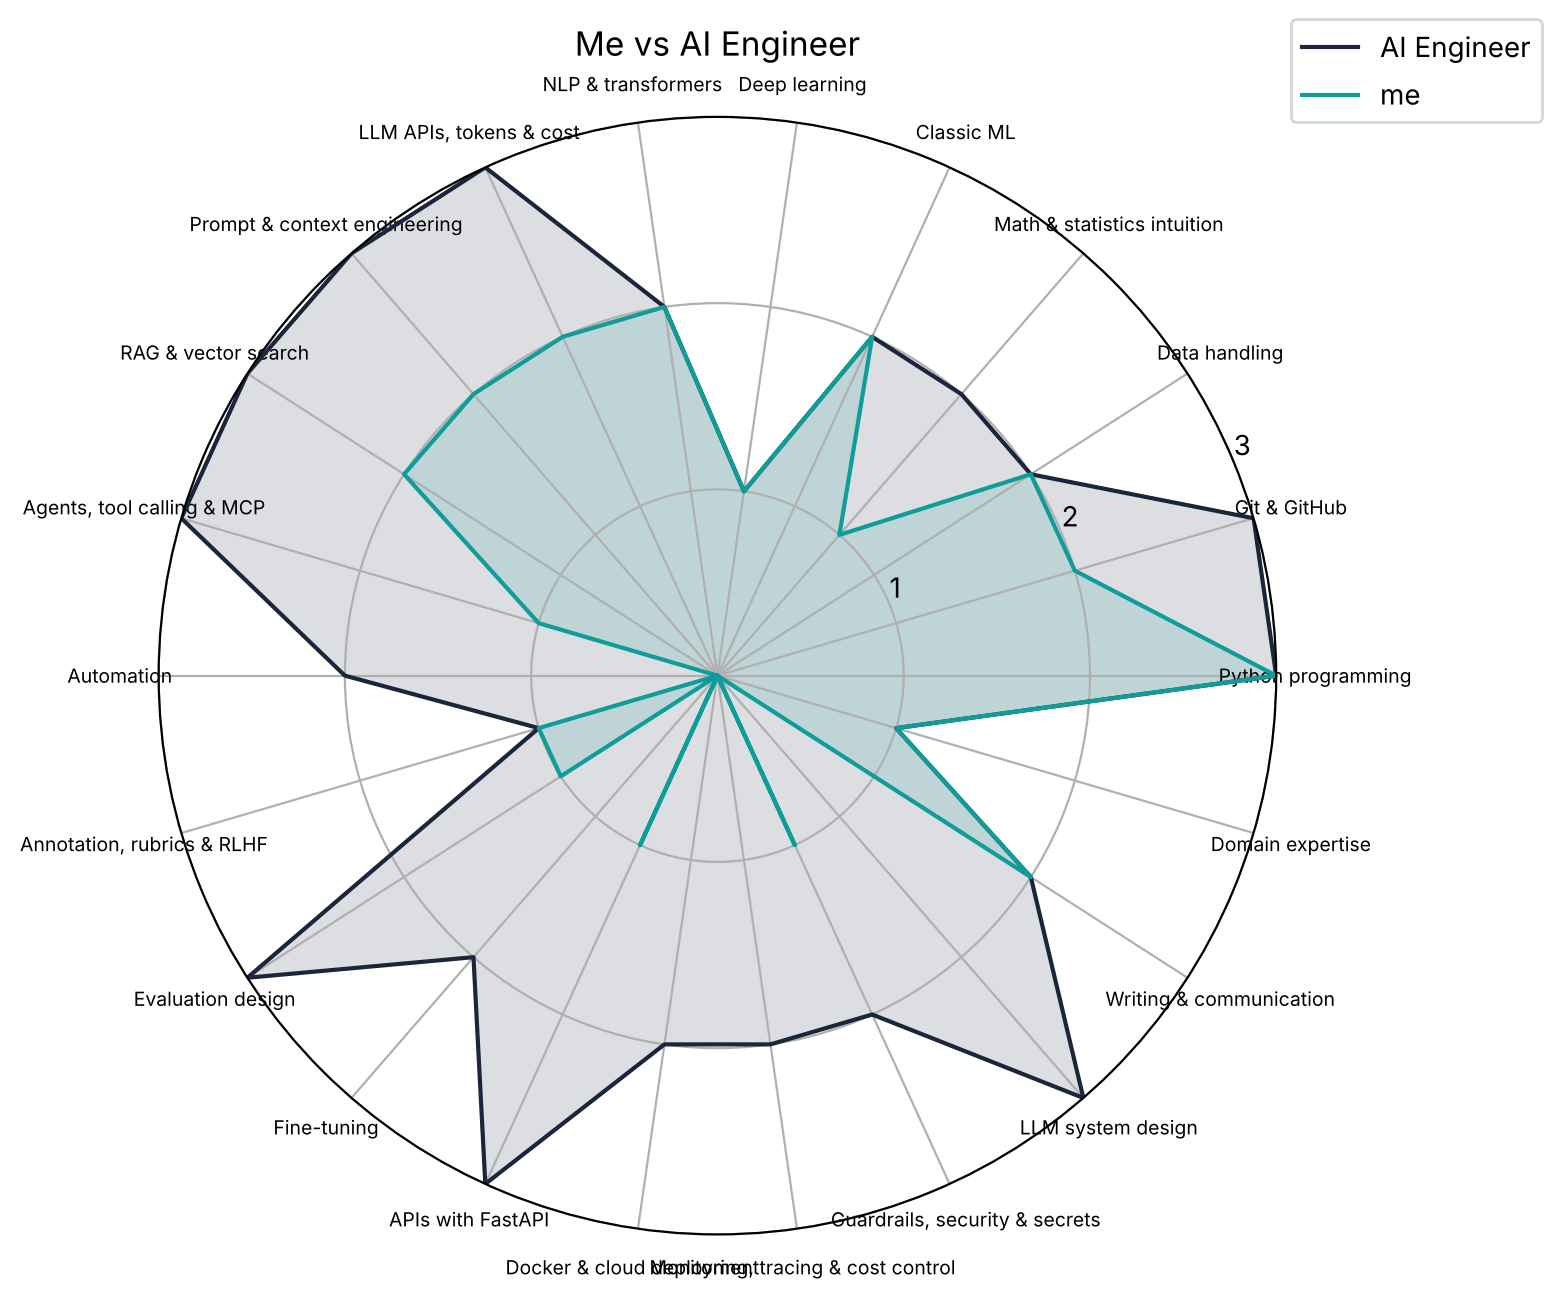

In [5]:
TARGET = "AI Engineer"
labels = matrix.skill.str.split(" \\(").str[0]            # shorter labels
angles = np.linspace(0, 2 * np.pi, len(matrix), endpoint=False).tolist()
angles += angles[:1]
fig = plt.figure(figsize=(8, 8)); ax = plt.subplot(polar=True)
for series, colour, name in [(matrix[TARGET], "#1b263b", TARGET), (matrix.me, "#0f9d9a", "me")]:
    vals = series.tolist() + series.tolist()[:1]
    ax.plot(angles, vals, color=colour, label=name); ax.fill(angles, vals, color=colour, alpha=0.15)
ax.set_xticks(angles[:-1], labels, fontsize=7); ax.set_yticks([1, 2, 3]); ax.set_ylim(0, 3)
ax.legend(loc="upper right", bbox_to_anchor=(1.25, 1.1)); ax.set_title(f"Me vs {TARGET}")
plt.tight_layout(); plt.show()

## Step 6 — the biggest gaps for your target role

Sort the skills by gap size and show which module teaches each one.

In [6]:
matrix["gap"] = (matrix[TARGET] - matrix.me).clip(lower=0)
top_gaps = matrix[matrix.gap > 0].sort_values(["gap", TARGET], ascending=False)[["skill", "module", TARGET, "me", "gap"]]
top_gaps

,skill,module,AI Engineer,me,gap
19,LLM system design,"14, 15",3,0,3
10,"Agents, tool calling & MCP",10,3,1,2
13,Evaluation design (evals),"12, 14",3,1,2
15,APIs with FastAPI,14,3,1,2
11,"Automation (n8n, webhooks)",11,2,0,2
14,Fine-tuning (LoRA/QLoRA),13,2,0,2
16,Docker & cloud deployment,14,2,0,2
17,"Monitoring, tracing & cost control",14,2,0,2
1,Git & GitHub,00,3,2,1
7,"LLM APIs, tokens & cost",07,3,2,1


## Step 7 — which roles are similar?

If two roles need similar skills, moving between them is easier. **Cosine similarity** between the roles' requirement columns measures this (1 = identical profile).

In [7]:
from sklearn.metrics.pairwise import cosine_similarity
sim = pd.DataFrame(cosine_similarity(matrix[ROLES].T.values), index=ROLES, columns=ROLES)
sim.round(2)

,AI Trainer / Annotator,Prompt Engineer,AI Engineer,ML Engineer,MLOps / LLMOps,AI Product Manager
AI Trainer / Annotator,1.00,0.80,0.53,0.57,0.37,0.82
Prompt Engineer,0.80,1.00,0.88,0.79,0.71,0.92
AI Engineer,0.53,0.88,1.00,0.90,0.92,0.81
ML Engineer,0.57,0.79,0.90,1.00,0.88,0.76
MLOps / LLMOps,0.37,0.71,0.92,0.88,1.00,0.71
AI Product Manager,0.82,0.92,0.81,0.76,0.71,1.00


## Step 8 — turn gaps into a weekly plan

A simple rule: each level of gap needs about **6 hours** of study and practice (a rough guess — adjust it). With a fixed number of hours per week we fill weeks in order of biggest gap first, and print the plan.

In [8]:
HOURS_PER_LEVEL, HOURS_PER_WEEK = 6, 8
tasks = [(r.skill, r.module, int(r.gap) * HOURS_PER_LEVEL) for r in top_gaps.itertuples()]
plan, week, left = [], 1, HOURS_PER_WEEK
for skill, module, hours in tasks:
    while hours > 0:
        h = min(hours, left)
        plan.append({"week": week, "skill": skill, "module": module, "hours": h})
        hours -= h; left -= h
        if left == 0:
            week, left = week + 1, HOURS_PER_WEEK
plan = pd.DataFrame(plan)
print(f"About {plan.week.max()} weeks at {HOURS_PER_WEEK} h/week to close all gaps for {TARGET}.")
plan.groupby("week").agg(skills=("skill", lambda s: " + ".join(dict.fromkeys(s))), hours=("hours", "sum")).head(12)

About 18 weeks at 8 h/week to close all gaps for AI Engineer.


,skills,hours
week,,
1,LLM system design,8
2,LLM system design,8
3,"LLM system design + Agents, tool calling & MCP",8
4,"Agents, tool calling & MCP + Evaluation design...",8
5,Evaluation design (evals),8
6,Evaluation design (evals) + APIs with FastAPI,8
7,"APIs with FastAPI + Automation (n8n, webhooks)",8
8,"Automation (n8n, webhooks)",8
9,"Automation (n8n, webhooks) + Fine-tuning (LoRA...",8


## Recap

- A skills matrix turns a vague goal ("get into AI") into specific gaps with modules to study.
- Readiness and radar charts show which role you are closest to *today* — a good first application target.
- Similar roles share skills, so a first job in one is a bridge to another.
- Save your plan: `plan.to_csv("my_plan.csv", index=False)` and re-run this notebook monthly.

The same calculation is in `excel/skills-matrix.xlsx` (Self-assessment sheet, with live formulas) and `code/skills_gap.py`.